In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm
from scipy.spatial import ConvexHull, convex_hull_plot_2d
import shapely
from shapely import Polygon, Point
from scipy.optimize import curve_fit
from matplotlib.collections import LineCollection
import re
from scipy import stats
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.interpolate import CubicSpline
from numpy import linalg
import yt
import matplotlib as mpl
from scipy.spatial import QhullError

In [2]:
out0 = 14400
outf = 500000
dout = 14400 # get data for each hour
outs = np.arange(out0, outf, dout)
data_names = [str(x) for x in outs]
print(outs)

[ 14400  28800  43200  57600  72000  86400 100800 115200 129600 144000
 158400 172800 187200 201600 216000 230400 244800 259200 273600 288000
 302400 316800 331200 345600 360000 374400 388800 403200 417600 432000
 446400 460800 475200 489600]


In [3]:
def setup_fs_data(s_data, f_data):
    s_data['split'] = 1 # 1 = yes split
    f_data['fuse'] = 1
    s_data['step_split'] = ((s_data['time_split'] / 0.25) / 400).round().astype(int) * 400
    f_data['step_fuse'] = ((f_data['time_fuse'] / 0.25) / 400).round().astype(int) * 400
    s_data['hour_split'] = (np.floor(s_data['time_split']) / (60 ** 2)).round().astype(int)
    f_data['hour_fuse'] = (np.floor(f_data['time_fuse']) / (60 ** 2)).round().astype(int)
    s_data['hour_split'] = s_data['hour_split'].replace(0, 1)
    f_data['hour_fuse'] = f_data['hour_fuse'].replace(0, 1)
    s_data['output_split'] = s_data['hour_split'] * 14400
    f_data['output_fuse'] = f_data['hour_fuse'] * 14400
    s_data = s_data[s_data['output_split'] < outf]
    f_data = f_data[f_data['output_fuse'] < outf]

    return s_data, f_data

def readin_data(run_name):
    path = '/Users/laurenyan/Documents/' + run_name + '/'
    print('data from: ' + path)
    datas = {}
    
    for i in range(len(data_names)):
        ds = yt.load(path + 'plt' + data_names[i])
        doi = ds.all_data()
        dfi = doi.to_dataframe([('all', 'particle_unique_id'), ('all', 'particle_position_x'), ('all', 'particle_position_y'), ('all', 'particle_position_z'), ('all', 'particle_position'),  ('all', 'particle_cell_volume')])
        dfi = dfi.rename(columns={'particle_unique_id': 'unique_id', 'particle_position_x': 'x', 'particle_position_y': 'y', 'particle_position_z': 'z', 'particle_position': 'position', 'particle_cell_volume': 'cell_volume'})
        datas[int(data_names[i])] = dfi
    
    print(datas.keys())
    
    split_count = pd.read_csv(path + '/split_count.txt', names = ['count', 'time_split'])
    splits = pd.read_csv(path + 'splits.txt', names = ['unique_id', 'time_split'])
    fuse_count = pd.read_csv(path + 'fuse_count.txt', names = ['count', 'time_fuse'])
    fuses = pd.read_csv(path + 'fuses.txt', names = ['unique_id', 'time_fuse'])
    
    print(datas[14400].columns)

    splits, fuses = setup_fs_data(splits, fuses)
    # data for all outputs where event occurs
    out_fs = pd.concat([fuses['output_fuse'], splits['output_split']]).unique()
    data_fs_names = [str(x) for x in out_fs]
    datas_fs = {}
    
    for i in range(len(data_fs_names)):
        ds = yt.load(path + 'plt' + data_fs_names[i])
        doi = ds.all_data()
        dfi = doi.to_dataframe([('all', 'particle_unique_id'), ('all', 'particle_position_x'), ('all', 'particle_position_y'), ('all', 'particle_position_z'), ('all', 'particle_position'),  ('all', 'particle_cell_volume')])
        dfi = dfi.rename(columns={'particle_unique_id': 'unique_id', 'particle_position_x': 'x', 'particle_position_y': 'y', 'particle_position_z': 'z', 'particle_position': 'position', 'particle_cell_volume': 'cell_volume'})
        datas_fs[int(data_fs_names[i])] = dfi
    print(datas_fs.keys())

    return datas, datas_fs, split_count, splits, fuse_count, fuses

def make_rings(data, ring_width):
    """
    From data for points in network and width of rings to divide network by, returns vertices of convex hull and concentric rings
    and radius for rings approximated as circles.
    """
    hull = ConvexHull(data)
    vertices0_index = hull.vertices
    vertices0_index = np.append(vertices0_index, vertices0_index[0])
    vertices0 = data[vertices0_index]

    rings = [vertices0]

    vertices_current = vertices0
    while Polygon(vertices_current).area > 0:
        # make rings
        buffer = shapely.buffer(Polygon(vertices_current), - ring_width).exterior.coords
        vertices_smaller = np.zeros(np.shape(vertices0))
        i = 0
        for x,y in buffer:
            vertices_smaller[i][0] = x
            vertices_smaller[i][1] = y
            i += 1
        vertices_current = vertices_smaller[~np.all(vertices_smaller == 0, axis=1)]
        rings.append(vertices_current)
    rings = rings[:-1] # remove last zero area polygon
    rings = rings[::-1]
    
    r = []
    for ring in rings:
        area = Polygon(ring).area
        r.append(np.sqrt(area / np.pi)) 

    return rings, r

def density(data, rings):
    """
    From data for points in a network and concentric rings dividing up network,
    returns density of points in each ring.
    """
    density = [0]
    
    for point in data:
        # inner most density is separate since it is not a ring
        if shapely.within(Point(point), Polygon(rings[0])):
            density[0] += 1
    density[0] /= Polygon(rings[0]).area
    
    j = 1        
    for ring in rings[1:]:
        # calculate density of each ring
        density.append(0)
        for point in data:
            if Polygon(ring).contains(Point(point)) and ~shapely.within(Point(point), Polygon(rings[j - 1])):
                density[j] += 1
        density[j] /= (Polygon(ring).area - Polygon(rings[j - 1]).area)
        j += 1
    
    return np.array(density)

def sigmoid_r(r, K, L, r0, b):
    """
    sigmoid function with parameters L, r0, k, b. Fit to find wave front.
    """
    return K / (1 + np.exp(-L * (r0 - r))) + b

def sigmoid_t(t, K, L, tn):
    return K / (1 + np.exp(L * (tn - t)))

def gaussian(t, H, A, tn, s):
    """
    gaussian function with parameters H, A, tn, s. Fit to tip density in ring.
    """
    return H + A * np.exp(-(t - tn)**2 / (2 * s**2))

In [8]:
def make_plots(data_all, data_fs, fuses, splits, ring_width):
    """
    From list of data for points in network at different times and width of rings to divide network, 
    plots network at final time, tip and filament density in time and space, position of wave front, and calculates mean speed of wave front.
    """
    # fig, axs = plt.subplots(3, 5, figsize=(28, 14))
    fig1, ax1 = plt.subplots(figsize = (8,8))
    outf = list(data_all.keys())[-1]
    dataf = data_all[outf]
    times = np.array([int(t) * (0.25 / 3600) for t in data_all.keys()])
    rings, rs = make_rings(dataf[['x','y']].to_numpy(), ring_width) # make rings from convex hull of final network shape
    n_rings = len(rings)
    density_tip_sum = {}
    density_in_sum = {}
    tip_r = []
    in_r = []
    ring_tip_t = []
    ring_in_t = []
    tns = []
    in_sat = []
    hr_f = int(times[-1]) # last output hour
    data_s = {}
    data_f = {}
    density_s_sum = {}
    density_f_sum = {}
    ring_s_t = []
    ring_f_t = []
    tip_pull_x = np.zeros(len(times))
    tip_pull_v = np.zeros(len(times))
    tip_all_x = np.zeros(len(times))
    tip_all_v = np.zeros(len(times))
    vdrift = np.zeros(len(times))
    vdrift_pull = np.zeros(len(times))
    xdrift_pull = np.zeros(len(times))
    l_filament = 35
    dcell = 1.1
    pdry = 0.21
    pcarbon = 0.5
    CUE = 0.5
    gamma = dcell * pdry * pcarbon / CUE
    C_cost = []
    
    fig20, ax20 = plt.subplots()

    for r in range(n_rings):
        ring_tip_t.append({}) # one dictionary for each ring, will append density at each time
        ring_in_t.append({})
        ring_s_t.append({})
        ring_f_t.append({})

    dataf = data_all[outs[-1]][['x', 'y']].to_numpy()
    hullf = ConvexHull(dataf)
    tip_pull_i = hullf.vertices
    tip_pull_i = np.append(tip_pull_i, tip_pull_i[0])
    tip_pullf = dataf[tip_pull_i]
    origin = shapely.centroid(Polygon(tip_pullf))
    x0 = origin.x
    y0 = origin.y
    # axs[0,0].plot(x0, y0, 'c*')
    
    i = 0
    for out in data_all.keys():
        time = int(out * (0.25 / 3600))
        
        # sorting out split and fusion data
        if out in data_fs.keys():
            data_fs_n = data_fs[out]

            if out in fuses['output_fuse'].values:
                fuses_out = fuses[fuses['output_fuse'] == out]
                data_fs_n = data_fs_n.merge(fuses_out, on = "unique_id", how = "left")
            else:
                data_fs_n['fuse'] = np.nan
            
            if out in splits['output_split'].values:
                splits_out = splits[splits['output_split'] == out]
                data_fs_n = data_fs_n.merge(splits_out, on = "unique_id", how = "left")
            else:
                data_fs_n['split'] = np.nan
            
            data_s[out] = data_fs_n[data_fs_n['split'] == 1] # particle data of all particles that split
            data_f[out] = data_fs_n[data_fs_n['fuse'] == 1] # particle data of all particles that fuse
    
            # density in each ring
            density_s = density(data_s[out][['x','y']].to_numpy(), rings)
            density_f = density(data_f[out][['x', 'y']].to_numpy(), rings)
        else:
            density_s = [0] * n_rings
            density_f = [0] * n_rings

        q = 0
        for ring in rings:
            ring_s_t[q][time] = density_s[q]
            ring_f_t[q][time] = density_f[q]
            q += 1
        
        data = data_all[out]
        
        # calculate carbon cost estimate
        C_cost.append(gamma * data['cell_volume'].sum())
        
        data = data[['x', 'y', 'position']]
        data_tip = data[data['position'] == 0]
        tip_all1 = data_tip[['x', 'y']].to_numpy()
        data_in = data[data['position'] != 0]
        data = data[['x', 'y']].to_numpy()

        # getting puller tips
        try:
            hull = ConvexHull(data)
            tip_pull_i = hull.vertices
            tip_pull_i = np.append(tip_pull_i, tip_pull_i[0])
            tip_pull1 = data[tip_pull_i]
        except QhullError as q:
            tip_pull1 = data
       
        # axs[1,0].plot(tip_pull1[:, 0], tip_pull1[:, 1], 'r--')

        # save first hour
        if i == 0:
            tip0x = data_tip['x'].to_numpy()
            tip0y = data_tip['y'].to_numpy()
            in0x = data_in['x'].to_numpy()
            in0y = data_in['y'].to_numpy()

            for ring in rings:
                ax1.plot(ring[:, 0], ring[:, 1], 'r--', lw = 1)
                # axs[0,0].plot(ring[:, 0], ring[:, 1], 'r--', lw = 1)

        # density in each ring
        density_tip = density(data_tip[['x','y']].to_numpy(), rings)
        density_in = density(data_in[['x', 'y']].to_numpy(), rings) * l_filament
        tip_r.append(density_tip)
        in_r.append(density_in)
        
        k = 0
        for ring in rings:
            ring_tip_t[k][time] = density_tip[k]
            ring_in_t[k][time] = density_in[k]
            k += 1
    
        # displacement of puller tips from previous time step
        if i > 0: # can't calculate velocity in first time step
            j = 0
            for pull in tip_pull0:
                xtip = pull[0]
                ytip = pull[1]
                
                # velocity of puller tips
                distances = np.linalg.norm(tip_pull1 - pull, axis=1)
                min_index = np.argmin(distances)
                tip_pull_dx[j] = distances[min_index]
                # axs[1,0].plot(xtip, ytip, 'k.')
                # axs[1,0].plot(tip_pull1[min_index][0], tip_pull1[min_index][1], 'k.')
                # axs[1,0].plot((xtip, tip_pull1[min_index][0]), (ytip, tip_pull1[min_index][1]), 'y--', lw = 0.3)

                # drift velocity of puller tips
                vtip = np.array([tip_pull1[min_index][0] - xtip, tip_pull1[min_index][1] - ytip])
                rtip = np.array([xtip-x0, ytip-y0])
                theta = np.dot(rtip, vtip) / (np.linalg.norm(rtip) * np.linalg.norm(vtip))
                vdrift_pull[i] += np.linalg.norm(vtip) * np.sin(theta) / 3600 # cm/s
                j += 1
            tip_pull_x[i] = tip_pull_x[i - 1] + np.mean(tip_pull_dx) # total displacement 
            tip_pull_v[i] = np.mean(tip_pull_dx) / 3600 # mean velocity over all tips cm/s
            vdrift_pull[i] /= len(tip_pull0)
            xdrift_pull[i] = xdrift_pull[i - 1] + vdrift_pull[i] * 3600 # cm
            
            j = 0
            for tip in tip_all0:
                xtip = tip[0]
                ytip = tip[1]
                
                # velocity of all tips
                distances = np.linalg.norm(tip_all1 - tip, axis=1)
                min_index = np.argmin(distances)
                tip_all_dx[j] = distances[min_index]
                ax20.plot(xtip, ytip, 'y.')
                ax20.plot(tip_all1[min_index][0], tip_all1[min_index][1], 'y.')
                ax20.plot((xtip, tip_all1[min_index][0]), (ytip, tip_all1[min_index][1]), 'm--', lw = 0.3)
                
                # drift velocity of all tips
                vtip = np.array([tip_all1[min_index][0] - xtip, tip_all1[min_index][1] - ytip])
                rtip = np.array([xtip-x0, ytip-y0])
                theta = np.dot(rtip, vtip) / (np.linalg.norm(rtip) * np.linalg.norm(vtip))
                vdrift[i] += np.linalg.norm(vtip) * np.sin(theta) / 3600
                j += 1
            tip_all_x[i] = tip_all_x[i - 1] + np.mean(tip_all_dx) # total displacement 
            tip_all_v[i] = np.mean(tip_all_dx) / 3600 # mean velocity over all tips
            vdrift[i] /= len(tip_all0)
        
        i += 1   
        tip_pull0 = tip_pull1 # saving tips to calculate velocity at next time
        tip_all0 = tip_all1
        tip_pull_dx = np.zeros(len(tip_pull0))
        tip_all_dx = np.zeros(len(tip_all0))
        
    # print('average puller tip velocity = ' + str(np.mean(tip_pull_v)))
    
    # l = 0 
    # for ring in rings:
    # #     axs[0,1].plot(times, ring_tip_t[l])
    # #     axs[0,1].set_title('tip density in times')
    #     axs[0,2].plot(times, ring_in_t[l])
    #     axs[0,2].set_title('filament density in times')
    # #     l += 1
    
    # plot first and last hour
    ax1.scatter(data_tip['x'].to_numpy(), data_tip['y'].to_numpy(), marker = 's')
    ax1.scatter(data_in['x'].to_numpy(), data_in['y'].to_numpy(), marker = 's')
    ax1.set_title('final network')
    ax1.scatter(tip0x, tip0y, marker = 's', color = 'y', label = 'initial network')
    ax1.scatter(in0x, in0y, marker = 's', color = 'y')
    ax1.legend()
    ax1.set_xlabel('x(cm)')
    ax1.set_ylabel('y(cm)')
    # axs[0,0].scatter(data_tip['x'].to_numpy(), data_tip['y'].to_numpy(), marker = 's')
    # axs[0,0].scatter(data_in['x'].to_numpy(), data_in['y'].to_numpy(), marker = 's')
    # axs[0,0].set_title('final network')
    # axs[0,0].scatter(tip0x, tip0y, marker = 's', color = 'y', label = 'initial network')
    # axs[0,0].scatter(in0x, in0y, marker = 's', color = 'y')
    # axs[0,0].legend()
    # axs[0,0].set_xlabel('x(cm)')
    # axs[0,0].set_ylabel('y(cm)')

    r0 = 0 # int(times[-1] / 2)
    try:
        t0 = np.nonzero(np.array(list(ring_tip_t[0].values())))[0][0]
    except IndexError as i:
        t0 = np.nonzero(np.array(list(ring_tip_t[1].values())))[0][0]
    
    # fitting sigmoid curve to filament density over time of each ring
    fig19, ax19 = plt.subplots(1,2, figsize = (14, 7))
    ring_in_t_fit = []
    omit_ring = [] # omit these rings for all averages over rings and with shifted time
    keep_ring = []
    p = 0
    for ring in ring_in_t:
        try:
            ring_t = np.array(list(ring.values()))[t0:]
            p0 = [np.max(ring_t), np.min(times), np.median(times)] # initial guess
            popt, pcov = curve_fit(sigmoid_t, times[t0:], ring_t, p0) # best fit parameters and covariance
            if popt[1] < 0:
                omit_ring.append(p)
                tns.append(0)
                ax19[0].plot(times[t0:], sigmoid_t(times[t0:], popt[0], popt[1], popt[2]))
            else:
                keep_ring.append(p)
                if popt[2] > times[-1]:
                    tns.append(0)
                    ax19[0].plot(times[t0:], sigmoid_t(times[t0:], popt[0], popt[1], popt[2]), 'r--')
                    ax19[0].plot(times[t0:], ring_t, 'r', alpha = 0.3)
                    ax19[0].vlines(popt[2], ymin = 0, ymax = np.max(ring_t), color ='r', alpha = 0.3, linestyle = '--')
                else:
                    tns.append(np.floor(popt[2]))
                    ax19[1].plot(times[t0:], sigmoid_t(times[t0:], popt[0], popt[1], popt[2]), 'b--')
                    ax19[1].plot(times[t0:], ring_t, 'b', alpha = 0.3)
                    ax19[1].vlines(popt[2], ymin = 0, ymax = np.max(ring_t), alpha = 0.3, color = 'b', linestyle = '--')
                in_sat.append(popt[0])
                ring_in_t_fit.append(sigmoid_t(times[t0:], popt[0], popt[1], popt[2]))
            
        except RuntimeError as e:
            omit_ring.append(p)
            tns.append(0)
        p += 1

    to_plot = r0 # int(np.argmax(tns > tns[0])) # get first ring where fit is good
    # stop_plot = int(np.where(np.array(tns) > (times[-1] - 5))[0][0]) # get last ring where tips fully pass through
    
    ax1.plot(rings[to_plot][:, 0], rings[to_plot][:, 1], 'g--', lw = 1)
    # ax1.plot(rings[stop_plot][:, 0], rings[stop_plot][:, 1], 'g--', lw = 1)
    # axs[0,0].plot(rings[to_plot][:, 0], rings[to_plot][:, 1], 'g--', lw = 1)
    # axs[0,0].plot(rings[stop_plot][:, 0], rings[stop_plot][:, 1], 'g--', lw = 1)
    
    # ring_tip_t_fit = []
    # for ring in ring_tip_t[to_plot:]:
    #     ring_t = list(ring.values())
    #     p0 = [0, np.max(ring_t), np.median(times), np.median(times)] # initial guess
    #     popt, pcov = curve_fit(gaussian, times, ring_t, p0) # best fit parameters and covariance
    #     ring_tip_t_fit.append(gaussian(times, popt[0], popt[1], popt[2], popt[3]))
    
    tip_r_lines = [np.column_stack([rs[to_plot:], tip_r[p][to_plot:]]) for p in np.arange(0,int(times[-1]), 1)]
    tip_r_lc = LineCollection(tip_r_lines, array = np.arange(0,int(times[-1]), 2), cmap = "plasma")
    fig2, (ax2, ax3) = plt.subplots(1, 2, figsize = (16, 7))
    ax2.add_collection(tip_r_lc)
    ax2.set_xlim(rs[to_plot], rs[-1])
    ax2.set_ylim(0, np.max(tip_r[-1]) + 200)
    ax2.set_title('tip density in space')
    ax2.set_xlabel(r'$r (cm)$')
    ax2.set_ylabel(r'$n (cm^{-2})$')
    fig2.colorbar(tip_r_lc, label="time", ax = ax3)
    # axs[1,1].add_collection(tip_r_lc)
    # axs[1,1].set_xlim(rs[to_plot], rs[-1])
    # axs[1,1].set_ylim(0, np.max(tip_r[-1]) + 200)
    # axs[1,1].set_title('tip density in space')
    # axs[1,1].set_xlabel(r'$r (cm)$')
    # axs[1,1].set_ylabel(r'$n (cm^{-2})$')
    # fig.colorbar(tip_r_lc, label="time", ax = axs[1,1])
    in_r_lines = [np.column_stack([rs[to_plot:], in_r[p][to_plot:]]) for p in np.arange(0,int(times[-1]), 1)]
    in_r_lc = LineCollection(in_r_lines, array = np.arange(0,int(times[-1]), 2), cmap = "plasma")
    # fig3, ax3 = plt.subplots()
    ax3.add_collection(in_r_lc)
    ax3.set_xlim(rs[to_plot], rs[-1])
    ax3.set_ylim(0, np.max(in_r[-1][to_plot:]) + 200)
    ax3.set_title('filament density in space')
    ax3.set_xlabel(r'$r (cm)$')
    ax3.set_ylabel(r'$\rho (\mu m cm^{-2})$')
    # plt.colorbar(in_r_lc, label="time")
    # axs[1,2].add_collection(in_r_lc)
    # axs[1,2].set_xlim(rs[to_plot], rs[-1])
    # axs[1,2].set_ylim(0, np.max(in_r[-1][to_plot:]) + 200)
    # axs[1,2].set_title('filament density in space')
    # axs[1,2].set_xlabel(r'$r (cm)$')
    # axs[1,2].set_ylabel(r'$\rho (\mu m cm^{-2})$')
    # fig.colorbar(in_r_lc, label="time", ax = axs[1,2])

    # ring_tip_t_fit_lines = [np.column_stack([times - tns[l + to_plot], ring_tip_t_fit[l]]) for l in range(to_plot, to_plot)]
    stop_plot = len(rs) - 1
    norm = mpl.colors.Normalize(rs[to_plot], rs[stop_plot])
    cmap = mpl.cm.ScalarMappable(norm=norm, cmap=mpl.cm.viridis)
    fig7, (ax7, ax8) = plt.subplots(1, 2, figsize = (16, 7))
    for l in range(to_plot, stop_plot):
        c = cmap.to_rgba(rs[l])
        ax7.plot(np.arange(times[0] - tns[l], times[-1] - tns[l] + 1),  list(ring_tip_t[l].values()), color = c)
        # p0 = [np.median(list(ring_tip_t[l].values())), np.max(list(ring_tip_t[l].values())), np.max(times - tns[l]), np.max(times - tns[l])] # initial guess
        # popt, pcov = curve_fit(gaussian, times - tns[l], list(ring_tip_t[l].values()), p0) # best fit parameters and covariance
        # density_tip_fit = gaussian(np.arange(times[0] - tns[l], times[-1] - tns[l], 0.3), popt[0], popt[1], popt[2], popt[3])
        # if (density_tip_fit != 0).all():
        #     ax7.plot(np.arange(times[0] - tns[l], times[-1] - tns[l], 0.3), density_tip_fit, color = c)
        #     ax7.scatter(times - tns[l], list(ring_tip_t[l].values()), color = c)
    ax7.set_xlim(-(times[-1] - tns[to_plot]), times[-1] - tns[to_plot] + 1)
    ax7.set_ylim(0, np.max(list(ring_tip_t[r0].values())[t0:]) + 1000)
    ax7.set_title('tip density in time')
    ax7.set_xlabel(r'$t - t_{0} (hrs)$')
    ax7.set_ylabel(r'$n (cm^{-2})$')
    # fig8, ax8 = plt.subplots()
    for l in range(to_plot, stop_plot):
        c = cmap.to_rgba(rs[l])
        ax8.plot(np.arange(times[0] - tns[l], times[-1] - tns[l] + 1),  list(ring_in_t[l].values()), color = c)
        # p0 = [max(list(ring_in_t[l].values())), np.min(list(ring_in_t[l].values())), np.median(times - tns[l]), np.median(list(ring_in_t[l].values()))] # initial guess
        # popt, pcov = curve_fit(sigmoid_t, times - tns[l], list(ring_in_t[l].values()), p0) # best fit parameters and covariance
        # density_in_fit = sigmoid_t(np.arange(times[0] - tns[l], times[-1] - tns[l], 0.3), popt[0], popt[1], popt[2], popt[3])
        # if (density_tip_fit != 0).all():
        #     ax8.plot(np.arange(times[0] - tns[l], times[-1] - tns[l], 0.3), density_in_fit, color = c)
        #     ax8.scatter(times - tns[l], list(ring_in_t[l].values()), color = c)
    # fig8.colorbar(cmap, ticks=rs[to_plot:stop_plot], ax = ax8, label = 'radius')
    ax8.set_xlim(-(times[-1] - tns[to_plot]), times[-1] - tns[to_plot] + 1)
    ax8.set_ylim(0, np.max(list(ring_in_t[r0].values())[t0:]) + 200)
    ax8.set_title('filament density in time')
    ax8.set_xlabel(r'$t - t_{0} (hrs)$')
    ax8.set_ylabel(r'$n (cm^{-2})$')
    fig7.colorbar(cmap, ticks=rs[to_plot:stop_plot], ax = ax8, label = 'radius')
    # plt.colorbar(ring_tip_lc, label="radius")
    # ring_tip_t_lines = [np.column_stack([times - tns[l], list(ring_tip_t[l].values())]) for l in range(to_plot, stop_plot)]
    # ring_tip_lc = LineCollection(ring_tip_t_lines, array=rs[to_plot:stop_plot], cmap="rainbow")
    # axs[0,1].add_collection(ring_tip_lc)
    # axs[0,1].set_xlim(-(times[-1] - tns[to_plot]), times[-1] - tns[to_plot])
    # axs[0,1].set_ylim(0, np.max(list(ring_tip_t[-1].values())[to_plot:]) + 200)
    # axs[0,1].set_title('tip density in time')
    # axs[0,1].set_xlabel(r'$t - t_{0} (hrs)$')
    # axs[0,1].set_ylabel(r'$n (cm^{-2})$')
    # fig.colorbar(ring_tip_lc, label="radius", ax = axs[0,1])
    # ring_in_t_fit_lines = [np.column_stack([times - tns[l], ring_in_t_fit[l]]) for l in range(to_plot, stop_plot)]
    # ring_in_t_lines = [np.column_stack([times - tns[l], list(ring_in_t[l].values())]) for l in range(to_plot, stop_plot)]
    # ring_in_lc = LineCollection(ring_in_t_lines, array=rs[to_plot:stop_plot], cmap="rainbow")
    # axs[0,2].add_collection(ring_in_lc)
    # axs[0,2].set_xlim(-(times[-1] - tns[to_plot]), times[-1] - tns[to_plot])
    # axs[0,2].set_ylim(0, np.max(list(ring_in_t[to_plot].values())) + 200)
    # axs[0,2].set_xlabel(r'$t - t_{0} (hrs)$')
    # axs[0,2].set_ylabel(r'$\rho (\mu m cm^{-2})$')
    # axs[0,2].set_title('filament density in time')
    # fig.colorbar(ring_in_lc, label="radius", ax = axs[0,2])

    shifted_t = np.arange(-int(times[-1] - tns[to_plot]), int(times[-1] - tns[to_plot]))
    # make dictionary with keys for shifted time
    for t in shifted_t: # range(-int(times[-1] - tns[to_plot]), int(times[-1] - tns[to_plot])):
        density_s_sum[t] = 0
        density_f_sum[t] = 0

    # calculating mean density of each ring at shifted time
    m = to_plot
    for ring_s, ring_f in zip(ring_s_t[to_plot:], ring_f_t[to_plot:]):
        if m not in omit_ring:
            tn = tns[m] # time to shift by
            for t in density_s_sum.keys():
                if t + tn in ring_s.keys():
                    density_s_sum[t] += ring_s[t + tn]
                else:
                    density_s_sum[t] += 0 # no data for this time, so network has not arrived there yet
            
            for t in density_f_sum.keys():
                if t + tn in ring_f.keys():
                    density_f_sum[t] += ring_f[t + tn]
                else:
                    density_f_sum[t] += 0
        m += 1

    density_s_mean = [x / len(keep_ring) for x in list(density_s_sum.values())]
    density_f_mean = [x / len(keep_ring) for x in list(density_f_sum.values())]
    
    # make dictionary with keys for shifted time
    for t in range(-int(times[-1] - tns[to_plot]), int(times[-1] - tns[to_plot])):
        density_tip_sum[t] = 0
        density_in_sum[t] = 0

    # calculating mean density of each ring at shifted time
    m = to_plot
    for ring_tip, ring_in in zip(ring_tip_t[to_plot:], ring_in_t[to_plot:]):
        if m not in omit_ring:
            tn = tns[m] # time to shift by
            for t in density_tip_sum.keys():
                if t + tn in ring_tip.keys():
                    density_tip_sum[t] += ring_tip[t + tn]
                else:
                    density_tip_sum[t] += 0 # no data for this time, so network has not arrived there yet
            
            for t in density_in_sum.keys():
                if t + tn in ring_in.keys():
                    density_in_sum[t] += ring_in[t + tn]
                elif ((t + tn) > np.array(list(ring_in.keys()))).all(): # after the network passes through the ring the density is constant
                    density_in_sum[t] += ring_in[np.max(list(ring_in.keys()))]
                else:
                    density_in_sum[t] += 0
        m += 1

    density_tip_mean = [x / len(keep_ring) for x in list(density_tip_sum.values())]
    density_in_mean = [x / len(keep_ring) for x in list(density_in_sum.values())]

    shifted_t_plot = np.arange(shifted_t[0], shifted_t[-1], 0.3)

    # fit tip density
    # p0 = [0, np.max(density_tip_mean), np.median(shifted_t), 1] # initial guess
    # popt, pcov = curve_fit(gaussian, shifted_t, density_tip_mean, p0) # best fit parameters and covariance
    # density_tip_fit = gaussian(shifted_t_plot, popt[0], popt[1], popt[2], popt[3])
    # axs[2,1].plot(shifted_t_plot, density_tip_fit)
    density_tip_cs = CubicSpline(shifted_t, density_tip_mean)
    # axs[2,1].plot(shifted_t, density_tip_cs(shifted_t))
    # axs[2,1].scatter(shifted_t, density_tip_cs(shifted_t, 1))
    dtip = density_tip_cs(shifted_t, 1)

    # fit filament density
    # p0 = [max(density_in_mean), np.min(density_in_mean), np.median(shifted_t), np.median(density_in_mean)] # initial guess
    # popt, pcov = curve_fit(sigmoid_t, shifted_t, density_in_mean, p0) # best fit parameters and covariance
    # density_in_fit = sigmoid_t(shifted_t_plot, popt[0], popt[1], popt[2], popt[3])
    # axs[2,2].plot(shifted_t_plot, density_in_fit)
    density_in_cs = CubicSpline(shifted_t, density_in_mean)
    # axs[2,2].plot(shifted_t, density_in_cs(shifted_t))
    # axs[2,2].scatter(shifted_t, density_in_cs(shifted_t, 1))
    din = density_in_cs(shifted_t, 1)

    
    # X, Y = np.meshgrid(density_in_cs(shifted_t), density_tip_cs(shifted_t))
    # U, V = np.meshgrid(din, dtip)
    # axs[0,4].streamplot(X, Y, U, V)

    fig9, ax9 = plt.subplots()
    ax9.plot(range(-int(times[-1] - tns[to_plot]), int(times[-1] - tns[to_plot])), density_tip_mean)
    ax9.set_title('mean tip density in time (n)')
    ax9.set_xlabel(r'$t - t_{0} (hrs)$')
    ax9.set_ylabel(r'$n (cm^{-2})$')
    fig10, ax10 = plt.subplots()
    ax10.plot(range(-int(times[-1] - tns[to_plot]), int(times[-1] - tns[to_plot])), density_in_mean)
    ax10.set_title(r'mean filament density in time ($\rho$)')
    ax10.set_xlabel(r'$t - t_{0} (hrs)$')
    ax10.set_ylabel(r'$\rho (\mu m cm^{-2})$')

    # stop_plot = int(np.where(np.array(tns) > (times[-1] - 5))[0][0])
    fig4, ax4 = plt.subplots()
    ax4.scatter([rs[i] for i in keep_ring[np.argmax(np.array(keep_ring) >= to_plot):]], np.array(in_sat)[np.argmax(np.array(keep_ring) >= to_plot):] * 1e-8)
    ax4.set_title('saturation density of rings')
    # ax4.hlines(np.mean(in_sat[to_plot:]) * 1e-8, xmin = rs[to_plot], xmax = rs[-1])
    ax4.set_xlabel('r(cm)')
    ax4.set_ylabel(r'$\rho (\mu m^{-1})$')
    # fig5, ax5 = plt.subplots()
    # # ax5.scatter(rs[to_plot:], np.array(in_sat[to_plot:]) * 1e-8)
    # ax5.set_title('saturation density of rings')
    # ax5.hlines(np.mean(in_sat[to_plot:]) * 1e-8, xmin = rs[to_plot], xmax = rs[-1], color = 'y', linestyle = '--', label = 'mean saturation density')
    # ax5.set_xlabel('r(cm)')
    # ax5.set_ylabel(r'$\rho (\mu m^{-1})$')
    # ax5.legend()
    # axs[2,3].scatter(rs[3:stop_plot], np.array(in_sat[3:stop_plot]) * 1e-8)
    # axs[2,3].set_title('saturation density of rings')
    # axs[2,3].hlines(np.mean(in_sat[3:stop_plot]) * 1e-8, xmin = rs[3], xmax = rs[stop_plot])
    # axs[2,3].set_xlabel('r(cm)')
    # axs[2,3].set_ylabel(r'$\rho (\mu m^{-1})$')

    fig14, ax14 = plt.subplots()
    ax14.scatter(times[1:], tip_pull_v[1:])
    ax_in3 = inset_axes(ax14, width="30%", height=2, loc="upper right")
    ax_in3.scatter(times, tip_pull_x)
    ax14.set_title('pulling tip speed')
    ax14.set_xlabel('t(hrs)')
    ax14.set_ylabel('v(cm/s)')
    ax14.hlines(np.mean(tip_pull_v[1:]), xmin = times[0], xmax = times[-1])
    ax_in3.set_xlabel('t(hrs)')
    ax_in3.set_ylabel('r(cm)')
    # axs[2,0].scatter(times[1:], tip_pull_v[1:])
    # ax_in3 = inset_axes(axs[2,0], width="30%", height=2, loc="upper right")
    # ax_in3.scatter(times, tip_pull_x)
    # axs[2,0].set_title('pulling tip speed')
    # axs[2,0].set_xlabel('t(hrs)')
    # axs[2,0].set_ylabel('v(cm/s)')
    # axs[2,0].hlines(np.mean(tip_pull_v[1:]), xmin = times[0], xmax = times[-1])
    # ax_in3.set_xlabel('t(hrs)')
    # ax_in3.set_ylabel('r(cm)')

    fig13, ax13 = plt.subplots()
    ax13.scatter(times[1:], vdrift_pull[1:], label = 'pulling tips')
    res = stats.linregress(times, xdrift_pull)
    ax_in4 = inset_axes(ax13, width="30%", height=2, loc="upper right")
    ax_in4.scatter(times, xdrift_pull)
    ax_in4.plot(times, np.array(times) * res.slope + res.intercept, 'r--')
    ax_in4.set_xlabel('t(hrs)')
    ax_in4.set_ylabel('r(cm)')
    ax13.scatter(times[1:], vdrift[1:])
    ax13.set_title('drift velocity = ' + f'{(res.slope / 3600):.1e}' + 'cm/s')
    ax13.set_xlabel('t(hrs)')
    ax13.set_ylabel(r'$v_{drift}(cm/s)$')
    ax13.hlines(np.mean(vdrift[1:]), xmin = times[0], xmax = times[-1], color = 'g')
    ax13.legend()
    # axs[2,4].scatter(times[1:], vdrift_pull[1:], label = 'pulling tips')
    # axs[2,4].scatter(times[1:], vdrift[1:])
    # axs[2,4].set_title('drift velocity')
    # axs[2,4].set_xlabel('t(hrs)')
    # axs[2,4].set_ylabel(r'$v_{drift}(cm/s)$')
    # axs[2,4].hlines(np.mean(vdrift[1:]), xmin = times[0], xmax = times[-1])
    # axs[2,4].legend()

    # axs[1,4].scatter(times, C_cost)
    # axs[1,4].set_title('Carbon cost estimate')
    # axs[1,4].set_xlabel('t(hrs)')
    # axs[1,4].set_ylabel('Carbon cost')

    # axs[2,3].plot(range(-int(times[-1] - tns[to_plot]), int(times[-1] - tns[to_plot])), np.array(density_tip_mean) * np.array(density_in_mean))
    # axs[2,3].set_title('mean tip density times filament density')

    # axs[1,4].scatter(density_tip_mean, density_s_mean)
    # res = stats.linregress(density_tip_mean, density_s_mean)
    # axs[1,4].plot(density_tip_mean, res.intercept + res.slope * np.array(density_tip_mean), 'r', label='constant of proportionality')
    # axs[1,4].legend()
    # axs[2,4].scatter(np.array(density_tip_mean) * np.array(density_in_mean), density_f_mean)
    # res = stats.linregress(np.array(density_tip_mean) * np.array(density_in_mean), density_f_mean)
    # axs[2,4].plot(np.array(density_tip_mean) * np.array(density_in_mean), res.intercept + res.slope * np.array(density_tip_mean) * np.array(density_in_mean), 'r', label='constant of proportionality')

    res = stats.linregress(density_tip_mean, density_s_mean)
    alpha = res.slope
    alphan = np.array(density_tip_mean) * alpha
    b = np.array(density_s_mean)
    fig11, ax11 = plt.subplots()
    ax11.plot(shifted_t, alphan, label = r'$\alpha n$')
    ax11.plot(shifted_t, b, label = '$b$')
    ax11.legend(loc = "upper right")
    ax_in1 = inset_axes(ax11, width="30%", height=2, loc="upper left")
    ax_in1.plot(np.array(density_tip_mean), res.intercept + alpha * np.array(density_tip_mean), 'r', label='constant of proportionality')
    ax_in1.scatter(density_tip_mean, b)
    ax_in1.yaxis.tick_right()
    ax_in1.yaxis.set_label_position("right")
    ax_in1.set_xlabel(r'$n(cm^{-2})$')
    ax_in1.set_ylabel(r'$b(hr^{-1}cm^{-2})$', ) 
    ax11.set_title(rf'$b = {alpha:.2f} n$')
    ax11.set_xlabel(r'$t - t_{0} (hrs)$')
    res = stats.linregress(np.array(density_tip_mean) * np.array(density_in_mean), density_f_mean)
    beta = res.slope
    betanrho = np.array(density_tip_mean) * np.array(density_in_mean) * beta
    a = np.array(density_f_mean)
    nrho = np.array(density_tip_mean) * np.array(density_in_mean)
    fig12, ax12 = plt.subplots()
    ax12.plot(shifted_t, betanrho, label = r'$\beta n\rho$')
    ax12.plot(shifted_t, a, label = '$a$')
    ax12.legend(loc = "upper right")
    ax_in2 = inset_axes(ax12, width="30%", height=2, loc="upper left")
    ax_in2.plot(nrho, res.intercept + beta * nrho, 'r', label='constant of proportionality')
    ax_in2.scatter(nrho, a)
    ax_in2.yaxis.tick_right()
    ax_in2.yaxis.set_label_position("right")
    ax_in2.set_xlabel(r'$n\rho(\mu m cm^{-4})$')
    ax_in2.set_ylabel(r'$a(hr^{-1}cm^{-2})$')
    ax12.set_title(rf'$a = {beta * 1e8:.2f} n\rho$') # convert mum/cm to 1/mum
    ax12.set_xlabel(r'$t - t_{0} (hrs)$')
    # axs[1,0].set_title('wavefront')
    # axs[1,0].set_xlabel('x(cm)')
    # axs[1,0].set_ylabel('y(cm)')

    ax4.hlines(2 * 1e-8 * alpha / beta, xmin = rs[r0], xmax = rs[-1], color = 'r', linestyle='--', label = r'$\frac{2\alpha}{\beta} = $' + f'{2 * 1e-8 * alpha / beta:.5f}')
    ax4.legend(loc = 'lower left')
    ax4.set_xlim(rs[r0], rs[-1])
    # axs[2,3].hlines(2 * 1e-8 * alpha / beta, xmin = rs[3], xmax = rs[stop_plot], color = 'r', linestyle='--', label = r'$\frac{2\alpha}{\beta}$')
    # axs[2,3].legend(loc = 'lower left')

    pulse_max = max(tip_r, key = max)
    fig13, ax13 = plt.subplots()
    ax13.plot(rs, pulse_max)

    fig14, ax14 = plt.subplots()
    ax14.plot(rs, tip_r[-3])
    
    plt.tight_layout()
    # fig1.savefig('finalnetwork.png', dpi = 500, bbox_inches='tight')
    # fig2.savefig('densityspace.png', dpi = 500, bbox_inches='tight')
    # fig3.savefig('filamentspace.png', dpi = 500, bbox_inches='tight')
    # fig7.savefig('densitytime.png', dpi = 500, bbox_inches='tight')
    # fig8.savefig('filamenttime.png', dpi = 500, bbox_inches='tight')
    # plt.figure(1)
    # plt.savefig('finalnetwork.png', dpi = 500)
    # plt.figure(2)
    # plt.savefig('tipspace.png', dpi = 500)
    # plt.figure(3)
    # plt.savefig('filamentspace.png', dpi = 500)
    # plt.figure(4)
    # fig5.savefig('saturation.png', dpi = 500, bbox_inches='tight')
    # plt.figure(5)
    # plt.savefig('drift.png', dpi = 500)
    # plt.figure(6)
    # plt.savefig('saturation_2alphabeta.png', dpi = 500)

In [6]:
datas2, datas_fs2, split_count2, splits2, fuse_count2, fuses2 = readin_data('output_fungi_160_0')

yt : [INFO     ] 2026-03-04 15:20:04,107 Parameters: current_time              = 3600.0
yt : [INFO     ] 2026-03-04 15:20:04,107 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-03-04 15:20:04,107 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-03-04 15:20:04,108 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-03-04 15:20:04,187 Parameters: current_time              = 7200.0
yt : [INFO     ] 2026-03-04 15:20:04,188 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-03-04 15:20:04,188 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-03-04 15:20:04,188 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-03-04 15:20:04,281 Parameters: current_time              = 10800.0
yt : [INFO     ] 2026-03-04 15:20:04,282 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-03-04 15:20:04,282 Parameters: domain_left_edge          = [0. 

data from: /Users/laurenyan/Documents/output_fungi_160_0/


yt : [INFO     ] 2026-03-04 15:20:04,369 Parameters: current_time              = 14400.0
yt : [INFO     ] 2026-03-04 15:20:04,369 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-03-04 15:20:04,370 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-03-04 15:20:04,370 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-03-04 15:20:04,468 Parameters: current_time              = 18000.0
yt : [INFO     ] 2026-03-04 15:20:04,469 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-03-04 15:20:04,469 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-03-04 15:20:04,469 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-03-04 15:20:04,598 Parameters: current_time              = 21600.0
yt : [INFO     ] 2026-03-04 15:20:04,599 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-03-04 15:20:04,599 Parameters: domain_left_edge          = [0

dict_keys([14400, 28800, 43200, 57600, 72000, 86400, 100800, 115200, 129600, 144000, 158400, 172800, 187200, 201600, 216000, 230400, 244800, 259200, 273600, 288000, 302400, 316800, 331200, 345600, 360000, 374400, 388800, 403200, 417600, 432000, 446400, 460800, 475200, 489600])
Index(['unique_id', 'x', 'y', 'z', 'position', 'cell_volume'], dtype='str')


yt : [INFO     ] 2026-03-04 15:20:07,547 Parameters: current_time              = 108000.0
yt : [INFO     ] 2026-03-04 15:20:07,548 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-03-04 15:20:07,548 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-03-04 15:20:07,548 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-03-04 15:20:07,638 Parameters: current_time              = 111600.0
yt : [INFO     ] 2026-03-04 15:20:07,639 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-03-04 15:20:07,639 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-03-04 15:20:07,639 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-03-04 15:20:07,754 Parameters: current_time              = 115200.0
yt : [INFO     ] 2026-03-04 15:20:07,755 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-03-04 15:20:07,755 Parameters: domain_left_edge          =

dict_keys([331200, 345600, 417600, 432000, 446400, 460800, 475200, 489600, 14400, 43200, 158400, 187200, 201600, 216000, 230400, 259200, 273600, 288000, 302400, 316800, 360000, 374400, 388800, 403200])


/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_49767/1187996307.py:241: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(sigmoid_t, times[t0:], ring_t, p0) # best fit parameters and covariance


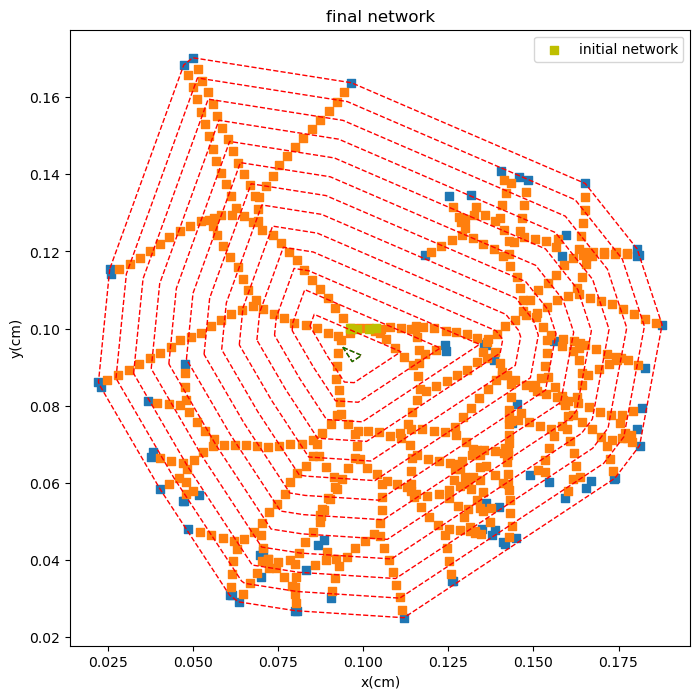

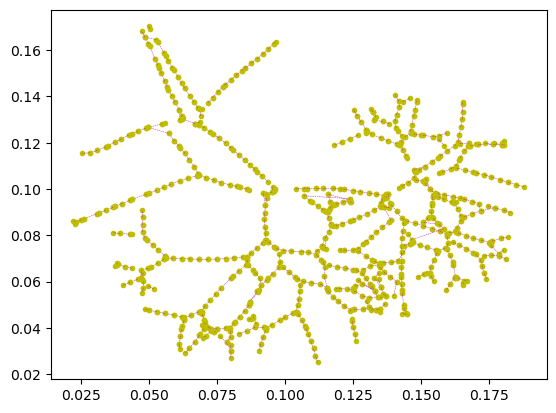

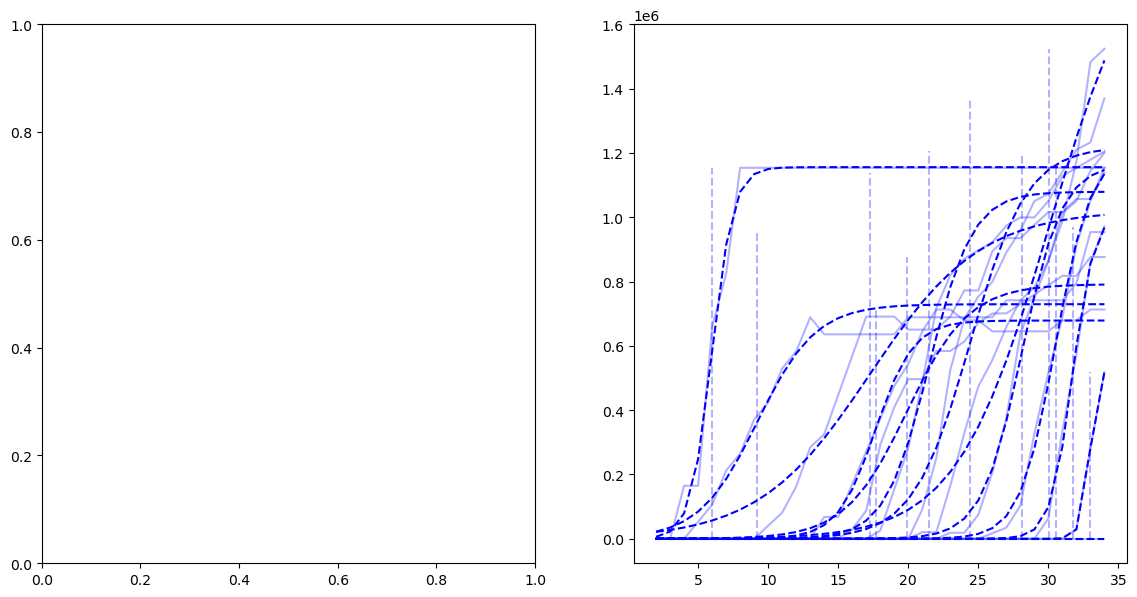

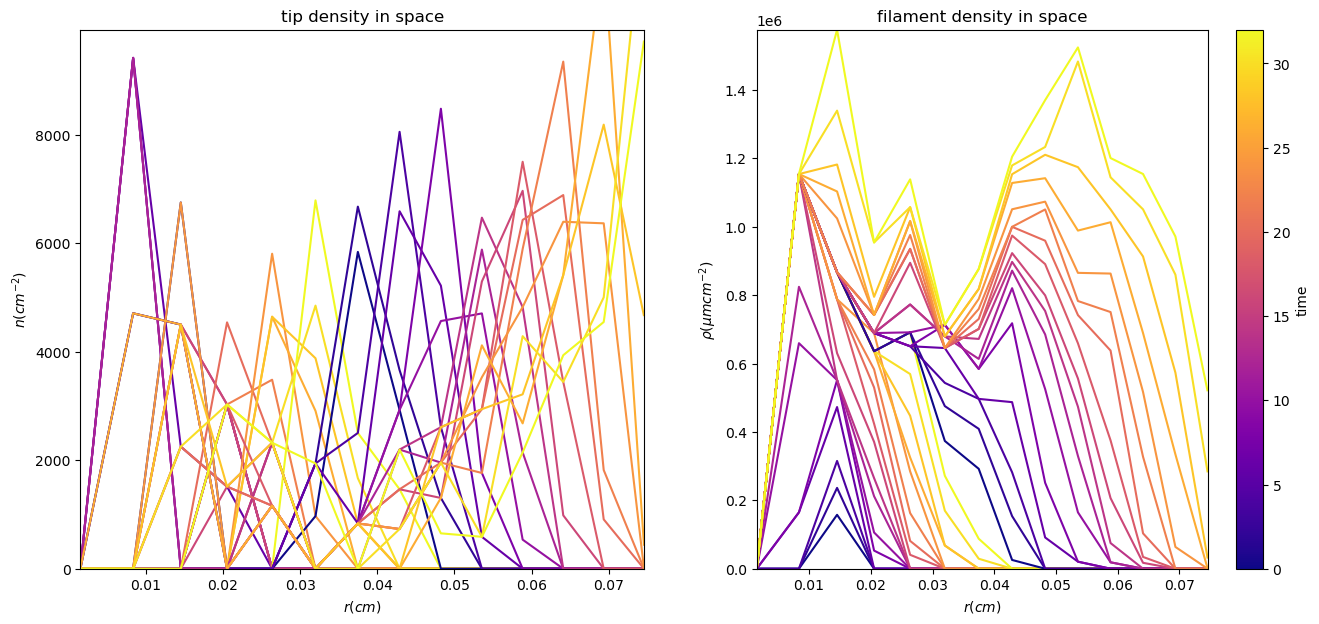

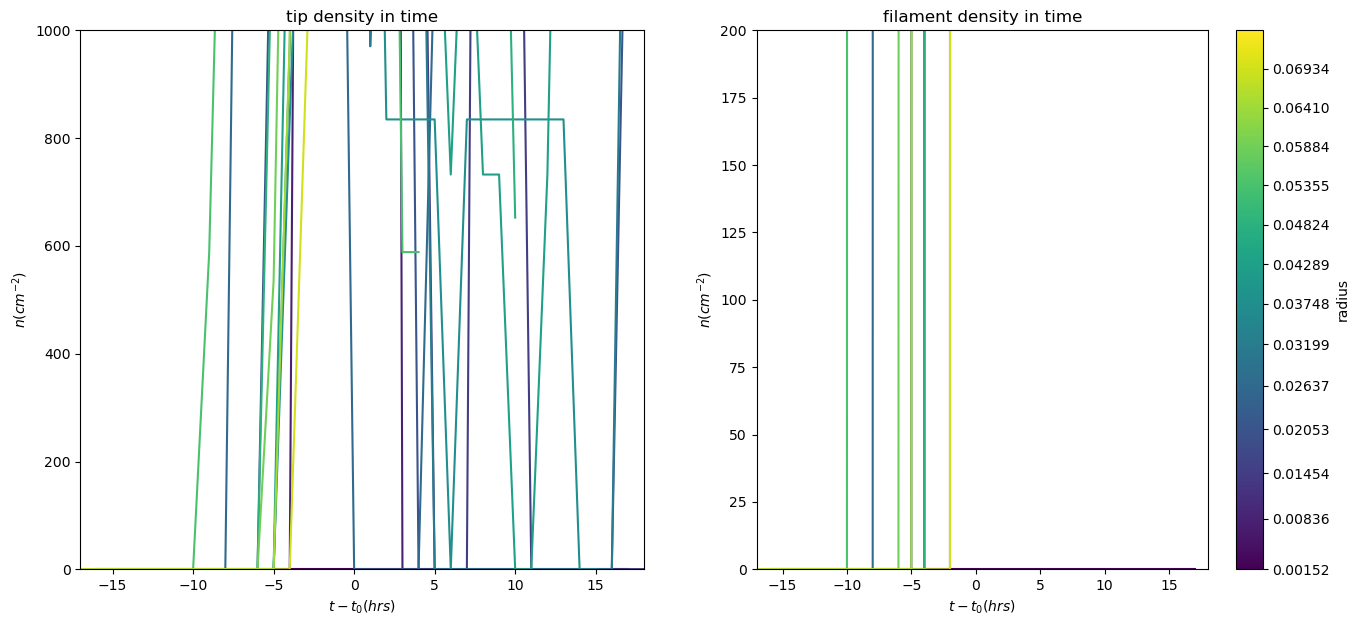

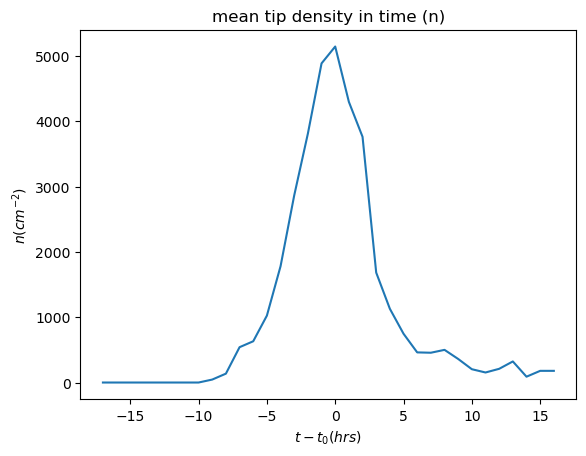

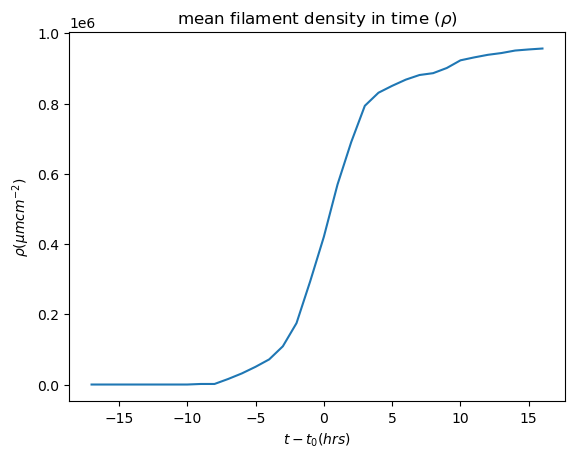

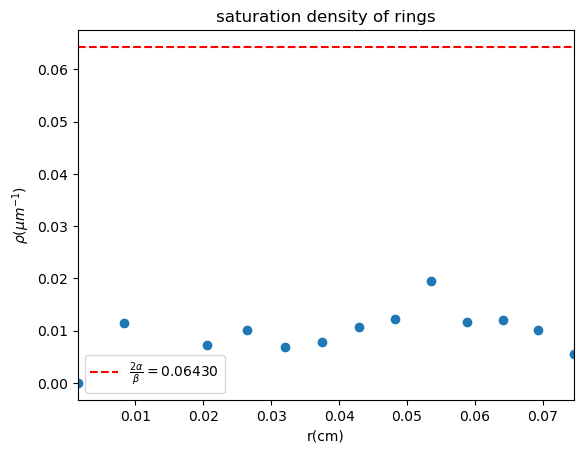

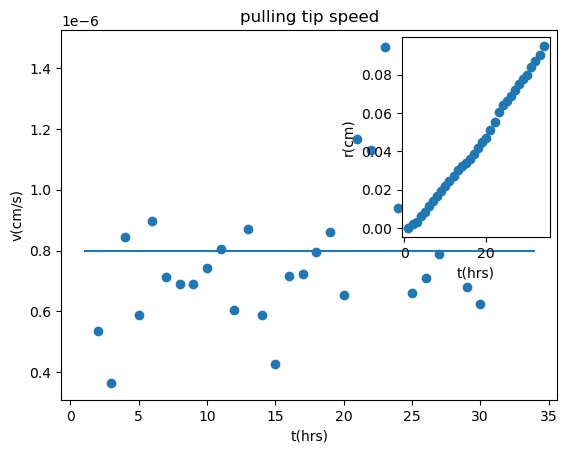

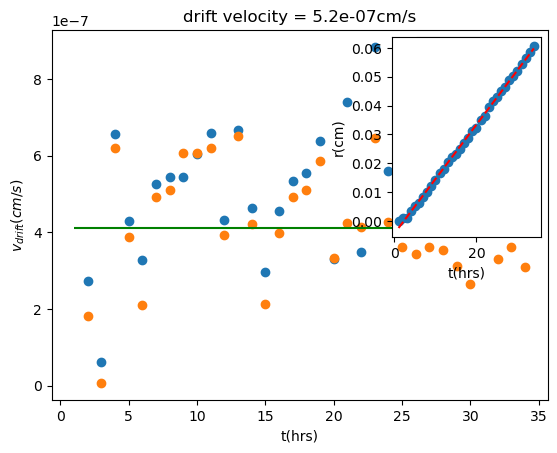

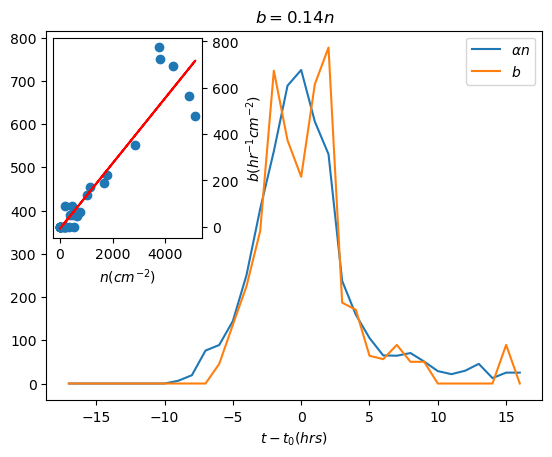

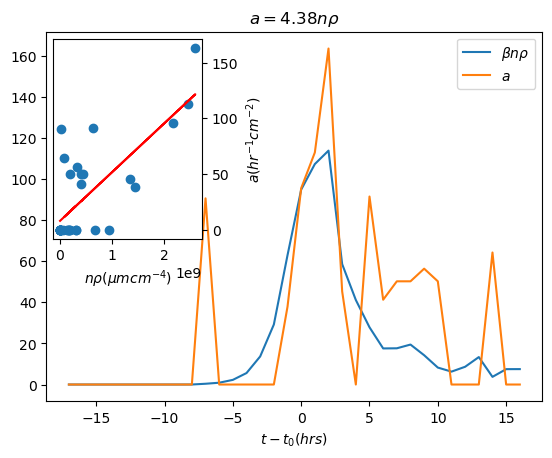

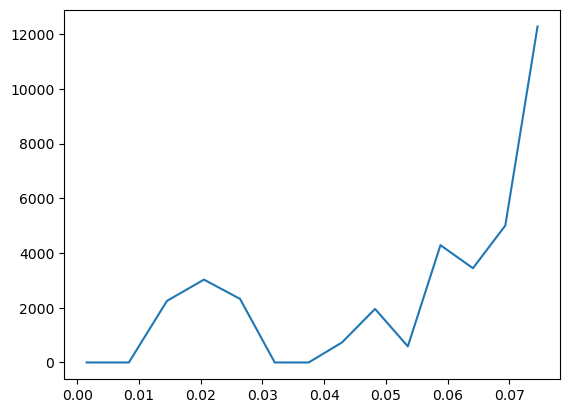

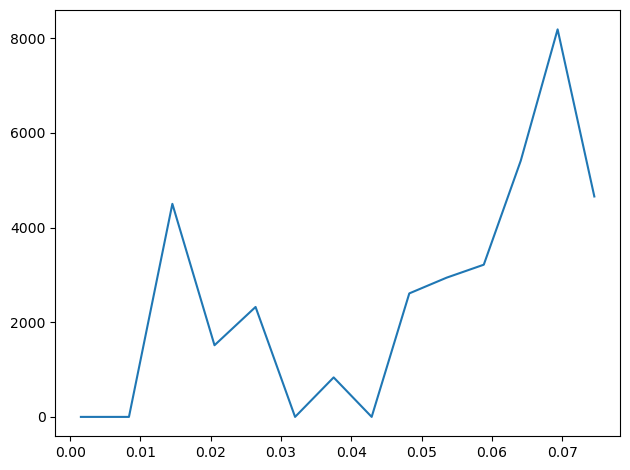

In [9]:
make_plots(datas2, datas_fs2, fuses2, splits2, 0.005)

In [ ]:
# plot first and last hour
figi, axi = plt.subplots()
axi.scatter(datas2[28800]['x'].to_numpy(), datas2[28800]['y'].to_numpy(), marker = 's')

In [ ]:
# event_outs = pd.concat([fuses['output_fuse'], splits['output_split']]).unique()
# print('Events occur in ' + str(len(event_outs)) + ' steps: ')
# for step in event_outs:
#     if step not in outs:
#         print(step) 
#     if step in outs:
#         print('*' + str(step) + '*')

In [ ]:
# # splits and fuses per hour
# splits_t = []
# for time in range(2,14):
#     split_time = splits[splits['hour'] == time]
#     splits_t.append(split_time['split'].sum())
# fuses_t = []
# for time in range(2,14):
#     fuse_time = fuses[fuses['hour'] == time]
#     fuses_t.append(fuse_time['fuse'].sum())

In [ ]:
# # data for all outputs where event occurs
# out_fs = pd.concat([fuses['output_fuse'], splits['output_split']]).unique()
# data_fs_names = [str(x) for x in out_fs]
# data_fss1 = {}
# for i in range(len(data_fs_names)):
#     dfi = pd.read_csv("/Users/laurenyan/Documents/bmx_default/"+data_fs_names[i]+".csv")
#     dfi = dfi.rename(columns={"Points:0": "x", "Points:1": "y", "Points:2": "z"})
#     data_fss1[int(data_fs_names[i])] = dfi

# print(data_fss1.keys())

In [ ]:
# for out, out_hr in zip(outs_fs, outs_fs_hr):
#     print(str(out) + '->' + str(out_hr))

In [ ]:
# def branch_fuse(data_fss, data_outs, fuses, splits, ring_width):
#     # add fuse and split data to particle data at the right output time and group into hours
#     outf = list(data_outs.keys())[-1]
#     dataf = data_outs[outf]
#     times = [int(t) * (0.25 / 3600) for t in data_outs.keys()]
#     hr_f = int(times[-1]) # last output hour
#     rings, rs = make_rings(dataf[['x','y']].to_numpy(), ring_width) # make rings from convex hull of final network shape
#     n_rings = len(rings)
#     data_s = {}
#     data_f = {}
#     ring_s_t = []
#     ring_f_t = []

#     for r in range(n_rings):
#         ring_s_t.append({}) # one dictionary for each ring, will append density at each time
#         ring_f_t.append({})
    
#     for out_n in data_fss.keys():
#         time = int(np.floor((out_n * 0.25) / (60 ** 2)))
#         data_fs_n = data_fss[out_n]

#         if out_n in fuses['output_fuse'].values:
#             fuses_out = fuses[fuses['output_fuse'] == out_n]
#             data_fs_n = data_fs_n.merge(fuses_out, on = "unique_id", how = "left")
#         else:
#             data_fs_n['fuse'] = np.nan
        
#         if out_n in splits['output_split'].values:
#             splits_out = splits[splits['output_split'] == out_n]
#             data_fs_n = data_fs_n.merge(splits_out, on = "unique_id", how = "left")
#         else:
#             data_fs_n['split'] = np.nan
        
#         data_fss[out_n] = data_fs_n
#         data_s[out_n] = data_fs_n[data_fs_n['split'] == 1] # particle data of all particles that split
#         data_f[out_n] = data_fs_n[data_fs_n['fuse'] == 1] # particle data of all particles that fuse
    
#         # density in each ring
#         density_s = density(data_s[['x','y']].to_numpy(), rings)
#         density_f = density(data_f[['x', 'y']].to_numpy(), rings)
            
#         k = 0
#         for ring in rings:
#             ring_s_t[k][time] = density_s[k]
#             ring_f_t[k][time] = density_f[k]
#             k += 1
            
#     # make dictionary with keys for shifted time
#     for t in range(-int(times[-1] - tns[to_plot]), int(times[-1] - tns[to_plot])):
#         density_s_sum[t] = 0
#         density_f_sum[t] = 0

#     # calculating mean density of each ring at shifted time
#     m = to_plot
#     for ring_s, ring_f in zip(ring_s_t, ring_f_t):
#         tn = tns[m] # time to shift by
#         for t in density_s_sum.keys():
#             if t + tn in ring_s.keys():
#                 density_s_sum[t] += ring_s[t + tn]
#             else:
#                 density_s_sum[t] += 0 # no data for this time, so network has not arrived there yet
        
#         for t in density_f_sum.keys():
#             if t + tn in ring_f.keys():
#                 density_f_sum[t] += ring_f[t + tn]
#             else:
#                 density_f_sum[t] += 0
#         m += 1

#     density_s_mean = [x / (n_rings - to_plot) for x in list(density_s_sum.values())]
#     density_f_mean = [x / (n_rings - to_plot) for x in list(density_f_sum.values())]
    
#     axs[0,3].scatter(range(-int(times[-1] - tns[to_plot]), int(times[-1] - tns[to_plot])), density_s_mean)
#     axs[0,3].set_title('mean branching rate')
#     axs[1,3].scatter(range(-int(times[-1] - tns[to_plot]), int(times[-1] - tns[to_plot])), density_f_mean)
#     axs[1,3].set_title('mean fusion rate')

In [ ]:
# only go through times where a split or fuse occurs
# keep rows for particles that split or fused
# group into hours
# calculate density
# average rate is events/hour/ring area

In [ ]:
# get particle data file for every hour and every time that a split or fuse occurs

In [ ]:
# use dictionary for all time series

In [ ]:
# plot fit of density vs space instead of lines

In [ ]:
# phase plane by vector plot of derivative for filament and tip density